In [22]:
import numpy as np 

def build_heatmap(coords, scores, weights, patch_size=512, scale_factor=16, save_path=None):
    """
    coords: Nx2 array (x, y)
    scores: N array con valores 0,1,2,3
    weights: N array con intensidad (ej. 0–1 o cualquier rango)
    Produce heatmap en RGB con colores por clase modulados por la intensidad.
    """

    # Escalar coordenadas
    coords = coords // scale_factor
    patch_size = patch_size // scale_factor

    max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width  = max_x - min_x + 1
    height = max_y - min_y + 1

    # Ajustar coordenadas
    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y

    # Heatmap RGB
    heatmap = np.zeros((height + patch_size, width + patch_size, 3), dtype=np.uint8)

    # Colores base
    color_map = {
        3: np.array([255,   0,   0]),  # Rojo
        2: np.array([255, 128,   0]),  # Naranja
        1: np.array([255, 255,   0]),  # Amarillo
        0: np.array([  0,   0, 255])   # Azul
    }

    # Dibujar los parches modulando por el peso
    for (x, y), s, w in zip(shifted_coords, scores, weights):

        base_color = color_map.get(int(s), np.array([255, 255, 255]))
        
        # Normalizar peso si viene fuera de 0–1
        # w_norm = (w - weights.min()) / (weights.max() - weights.min())
        w_norm = float(w)*10

        # Escalar color por intensidad
        color = (base_color * w_norm).clip(0, 255).astype(np.uint8)

        heatmap[y:y+patch_size, x:x+patch_size] = color

    img = Image.fromarray(heatmap, mode="RGB")

    if save_path:
        img.save(save_path)

    return img


In [23]:
# IMPORT LIBRARIES
import os 
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import pandas as pd 
from sklearn.model_selection import GroupShuffleSplit
from accelerate import Accelerator
from safetensors.torch import load_file

current_dir  = os.path.abspath(os.getcwd())# Directorio actual
sys.path.append(os.path.dirname(current_dir))

from utils.data_load import WSI_Dataset, create_file_label_df, collate_fn
from utils.train_utils import run_epoch
from utils.metrics_utils import log_epoch_metrics, save_metrics_to_csv
from utils.heatmap_utils import  overlay_heatmap_on_image, draw_gt_patches

from models.keep_model import get_keep_ia3_model
from models.CNN import CNNEmbedder

# DEFINE PATHS 
ckpt_path = "/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100"
folder_original_imgs = '/workspace/data/pandas/stitches'
num_img_show = 20

sicap_images_folder_path='/workspace/data/pandas/patches' #'/workspace/data/TCGA/patches'' #'/workspace/data/features_SICAP/patches' 
sicap_labels_df_path=  '/workspace/data/datos_PANDAS.xlsx' #  '/workspace/data/wsi_labels_changed_SICAP.xlsx' #'/workspace/data/features_PRAD/tcga_dataset.xlsx' # 
mask_folder= '/workspace/data/pandas/stitches' #"/workspace/data/annotation_masks_SICAP"
# GENERAL CONFIGURATION 
print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f" Usando dispositivo: {device}", flush = True)

# LOADING MODEL 
if "CNN" in ckpt_path:
    print(f"Model: CNN")
    model = CNNEmbedder(clasification_model='graph')
if "KEEP" in ckpt_path:
    print(f"Model: KEEP")
    model = get_keep_ia3_model(clasification_model='mlp', pretrain=False )
    model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)

# Cargar pesos
state_dict = load_file(os.path.join(ckpt_path,'best_model', "model.safetensors"), device="cpu")
model.load_state_dict(state_dict, strict=True)
#accelerator.load_state(ckpt_path)
print(" Pesos cargados correctamente")

loss = nn.BCELoss() 

# LOADING DATA
df_test = create_file_label_df(sicap_images_folder_path, sicap_labels_df_path, NAME = 'SICAP')
#df_test = df_test.head(5)
label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

# PARA PANDA 
gss_test = GroupShuffleSplit(test_size=0.10, n_splits=1, random_state=98)
train_val_idx, test_idx = next(gss_test.split(df_test.index, df_test["gleason_score"], groups=df_test["patients"]))

print("Loading embeddings for Inference ...")
sicap_data = WSI_Dataset(df_test, test_idx[0:20], inference_heatmap=True)
inference_loader = DataLoader(sicap_data, batch_size=32, shuffle=False, collate_fn=collate_fn, num_workers=0)

'''print("Loading embeddings for Inference ...")
inference_loader = DataLoader(WSI_Dataset(df_test, df_test.index, inference_heatmap=True), shuffle=False, batch_size=1, collate_fn=collate_fn)
'''

# INFERENCE IN MODEL
model, inference_loader = accelerator.prepare(model, inference_loader)
inference_metrics, inference_loss, _,_,_,test_outputs = run_epoch(model, inference_loader, device, accelerator, loss, None, 
                                                                mode='test',inference_heatmap=True, multilabel_prob_threshold=0.15, 
                                                                min_presence_threshold=0.2, secondary_ratio_threshold=0.2,alpha_pe=0, alpha_pc=0)   
# METRICS 
print(f"AUROC (Macro): {inference_metrics['multilabel']['auroc_macro']} \n")
print(f"AUROC (Weighted): {inference_metrics['multilabel']['auroc_weighted']} \n")
print(f"AUPRC (Macro): {inference_metrics['multilabel']['auprc_macro']} \n")
print(f"AUPRC (Weighted): {inference_metrics['multilabel']['auprc_weighted']} \n")

log_epoch_metrics("SICAP dataset", "Test", inference_metrics, inference_loss, os.path.join(ckpt_path, "heatmap_inference.txt"))
save_metrics_to_csv(inference_metrics, epoch=0,  filepath= os.path.join(ckpt_path, "heatmap_inference.csv"))


 *Starting General Configuration ...
 Usando dispositivo: cuda
Model: KEEP
Parámetros entrenables: 726565
 Pesos cargados correctamente
Procesando WSIs: 100%|██████████| 9216/9216 [00:09<00:00, 923.22it/s]
Loading embeddings for Inference ...
TEST: 100%|██████████| 1/1 [00:09<00:00,  9.05s/it]
AUROC (Macro): 0.9081253713606654 

AUROC (Weighted): 0.8821628045157458 

AUPRC (Macro): 0.8391483184545385 

AUPRC (Weighted): 0.8779603554340397 


=== Época SICAP dataset | TEST METRICS ===
Loss global: 0.3603

-- PRIMARY --
  Accuracy : 0.6500
  Precision (Micro)   : 0.6500
  Precision (Macro)   : 0.4833
  Precision (Weighted): 0.6233
  Recall (Micro)      : 0.6500
  Recall (Macro)      : 0.5595
  Recall (Weighted)   : 0.6500
  F1 Score (Micro)    : 0.6500
  F1 Score (Macro)    : 0.5080
  F1 Score (Weighted) : 0.6279
  Kappa               : 0.7131

-- SECONDARY --
  Accuracy : 0.5000
  Precision (Micro)   : 0.5000
  Precision (Macro)   : 0.3792
  Precision (Weighted): 0.4983
  Recall (Micro)

In [24]:
def build_heatmap_binary(coords, scores, weights,
                          height, width,
                          patch_size=512,
                          scale_factor=16):

    width  = int(width  / scale_factor)
    height = int(height / scale_factor)

    # tamaño real en 20x
    W20 = max(c[0] for c in coords) + patch_size
    H20 = max(c[1] for c in coords) + patch_size

    sx = width  / W20
    sy = height / H20

    masks = np.zeros((height, width), dtype=np.float32)
    m_weights = np.zeros((height, width), dtype=np.float32)

    for (x, y), s, w in zip(coords, scores, weights):

        # bbox en 20x
        x0_20, y0_20 = x, y
        x1_20 = x + patch_size
        y1_20 = y + patch_size

        # escalar a JPG
        x0 = int(x0_20 * sx)
        x1 = int(x1_20 * sx)
        y0 = int(y0_20 * sy)
        y1 = int(y1_20 * sy)

        # clip
        x0 = max(0, min(x0, width  - 1))
        x1 = max(0, min(x1, width))
        y0 = max(0, min(y0, height - 1))
        y1 = max(0, min(y1, height))

        if x0 < x1 and y0 < y1:
            masks[y0:y1, x0:x1] = s
            m_weights[y0:y1, x0:x1] += w.item()

    return masks, m_weights


In [25]:
from matplotlib import cm 

def heatmap_building(h,w, mask, w_mask, grades, slide_id, factor):
    heatmap = np.zeros((h//factor, w//factor, 3), dtype=np.float32)

    # Cargar tissue una sola vez
    #slide_id = slide_id.split('/')[-1]
    #tissue_path = os.path.join('/workspace/data/annotation_masks_SICAP',  f"{slide_id}")
    #print(f" Cargando tissue mask desde: {tissue_path} ")
    #tissue = np.array(Image.open(tissue_path))

    for index, pred_name in enumerate(grades):

        class_id = pred_name.item()

        # Máscara binaria
        mask_bin = (mask == class_id).astype(np.float32)

        # Máscara ponderada
        mask_pred = mask_bin * w_mask

        if mask_pred.max() == 0:
            continue

        # Normalizar a [0,1]
        mask_pred = mask_pred / mask_pred.max()

        # --- COLORES ---
        grade_colormaps = {
            0: cm.Blues,    # azul
            1: cm.YlOrBr,   #YlOrBr,   # amarillo
            2: cm.Oranges, # naranja
            3: cm.Reds     # rojo
        }

        color_map_fn = grade_colormaps.get(class_id, cm.Greys)
        color_map = color_map_fn(mask_pred)

        # Quitar alpha
        color_map = color_map[:, :, :3]

        # Fondo negro
        color_map[mask_pred == 0] = 0

        # Aplicar tissue mask
        #color_map[tissue == 0] = 0

        # Acumular (sumar heatmaps)
        heatmap += color_map


    # Clamp y convertir a uint8
    heatmap_join = np.clip(heatmap, 0, 1)
    heatmap_join = (heatmap_join * 255).astype(np.uint8)
    return heatmap_join

 Cargando WSI desde: /workspace/data/pandas/stitches/004dd32d9cd167d9cc31c13b704498af.png 
slide /workspace/data/pandas/patches/004dd32d9cd167d9cc31c13b704498af.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


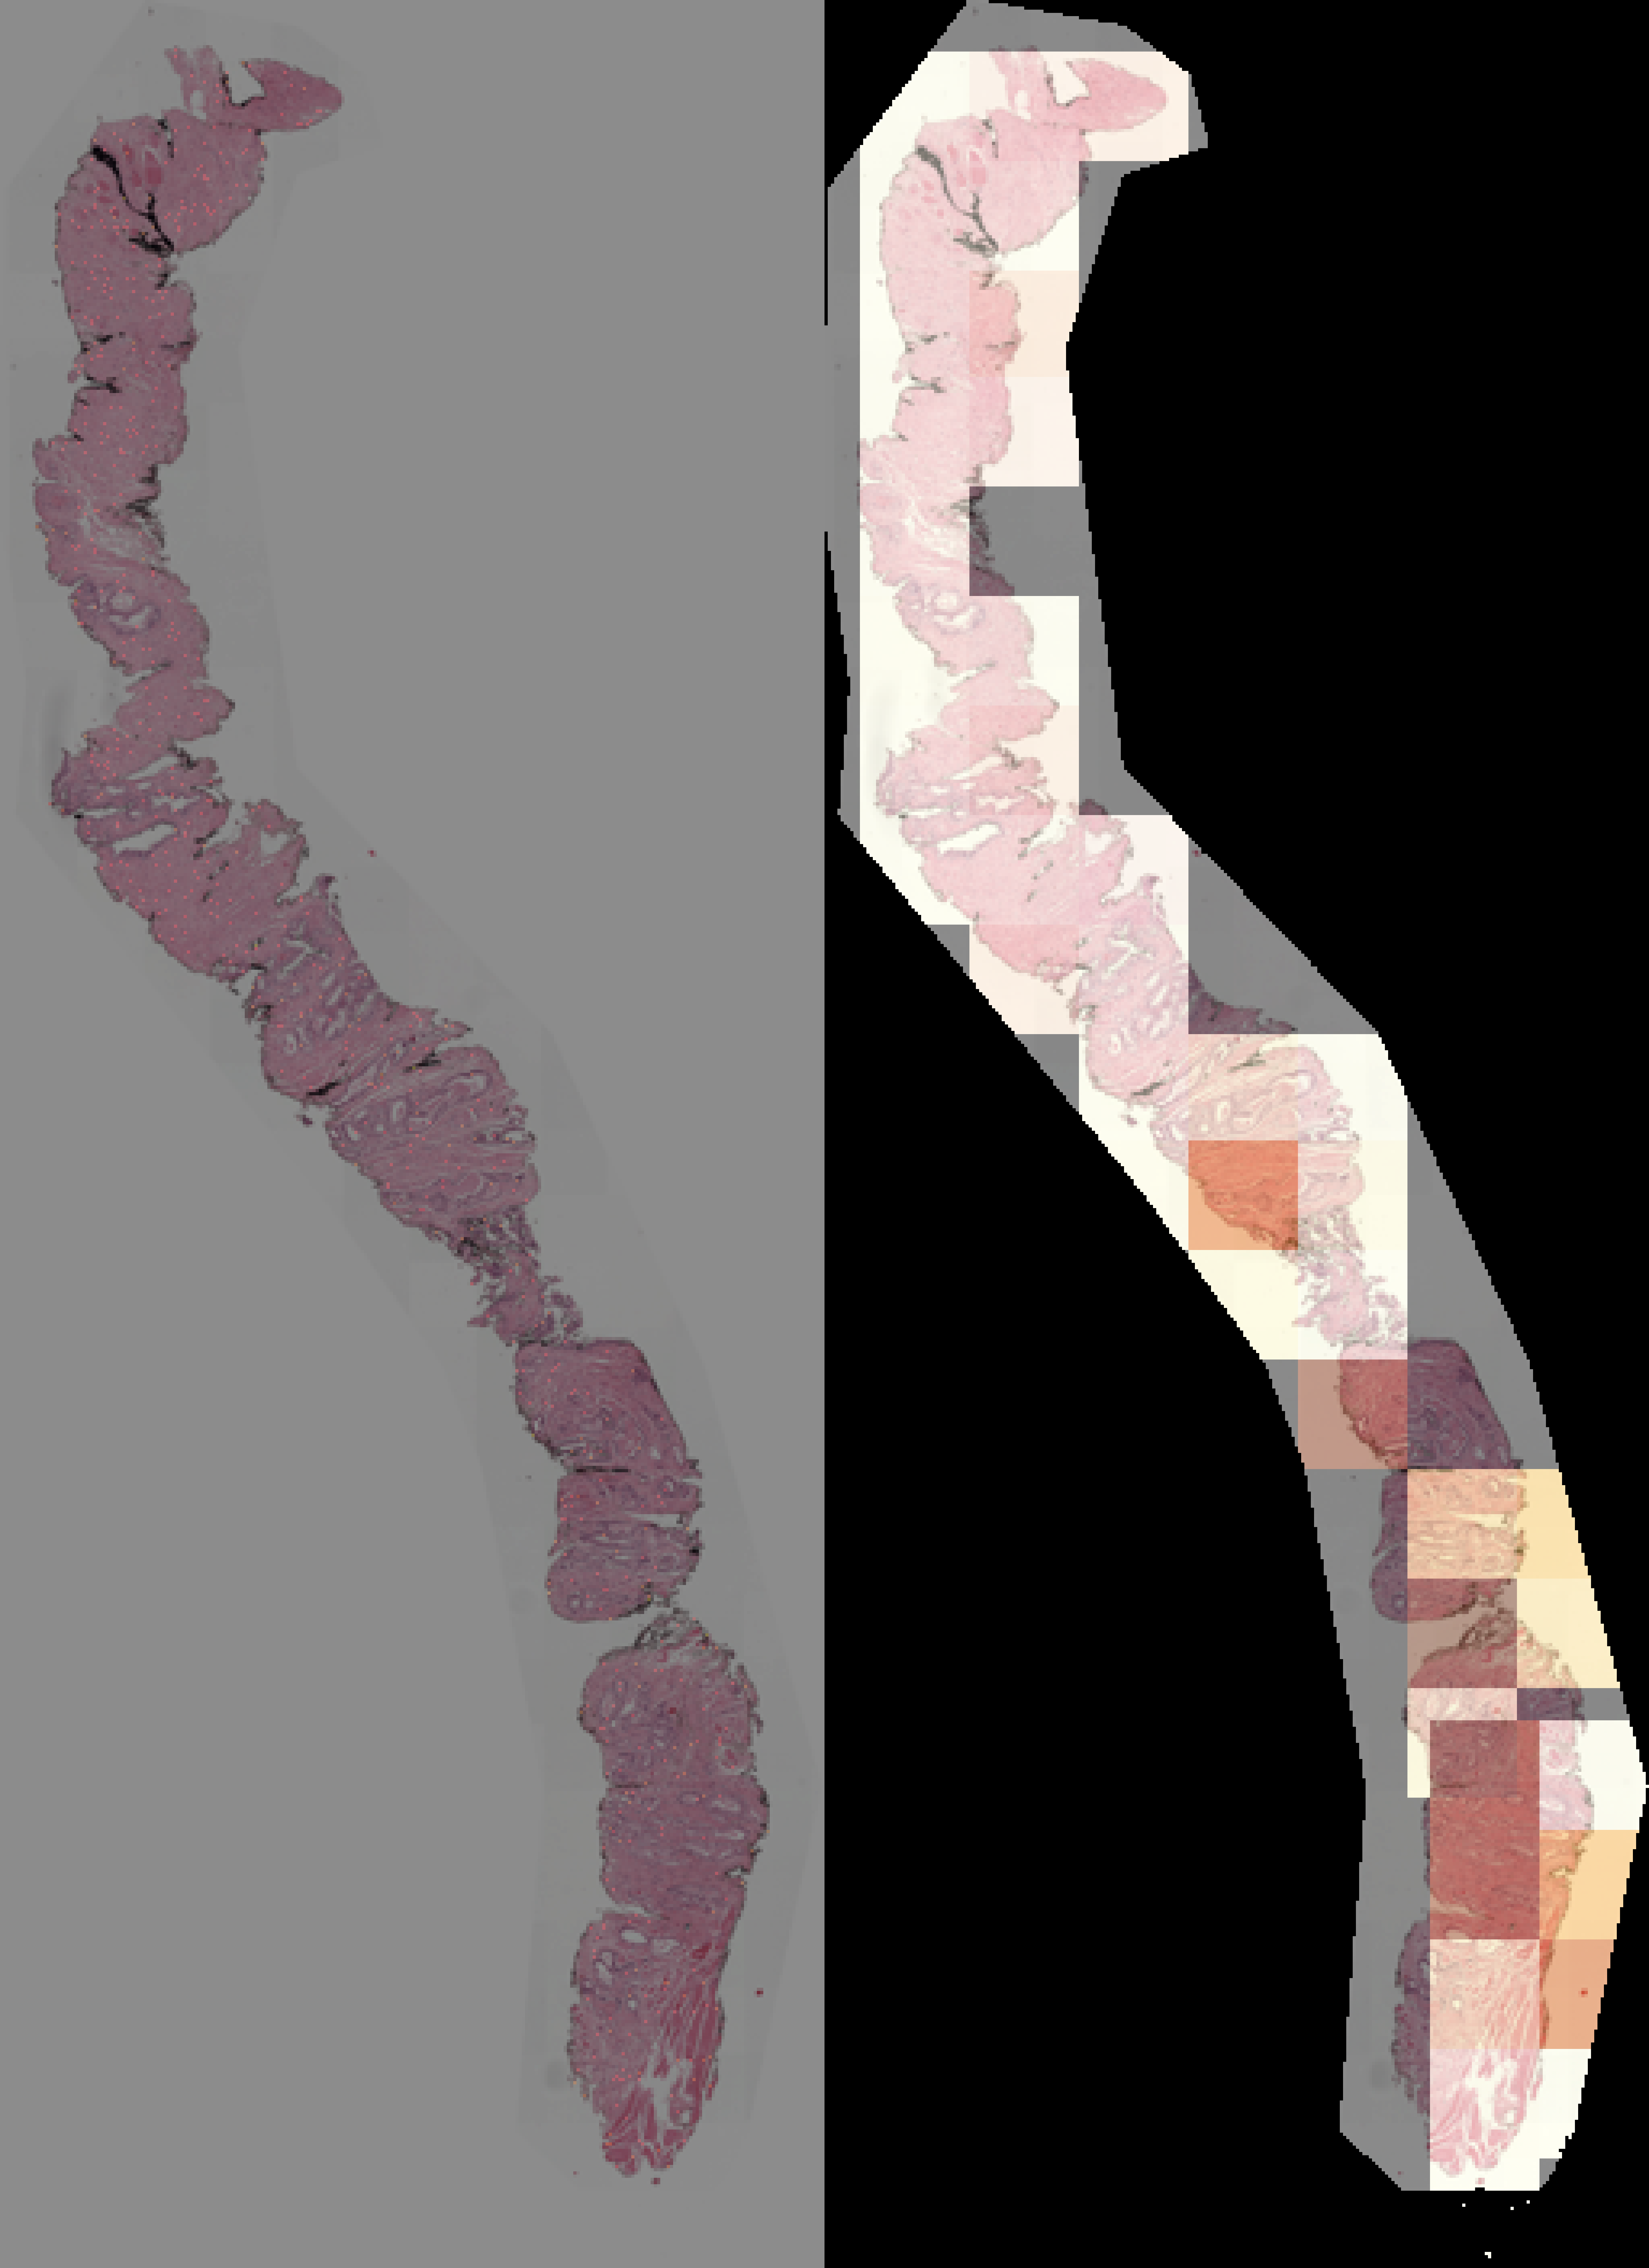

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/004dd32d9cd167d9cc31c13b704498af.png
 Cargando WSI desde: /workspace/data/pandas/stitches/005e66f06bce9c2e49142536caf2f6ee.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/006f4d8d3556dd21f6424202c2d294a9.png 


/usr/local/lib/python3.10/dist-packages/PIL/Image.py:3035: DecompressionBombWarning: Image size (155975680 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


slide /workspace/data/pandas/patches/006f4d8d3556dd21f6424202c2d294a9.h5
 Scores de la slide: Grado Primario = NC & Grado Secundario = NC.


Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/006f4d8d3556dd21f6424202c2d294a9.png
 Cargando WSI desde: /workspace/data/pandas/stitches/00a97615a51ba4c475bdec8505623bf9.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/01227af585a47c16680f927d21a7f06a.png 
slide /workspace/data/pandas/patches/01227af585a47c16680f927d21a7f06a.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 3.


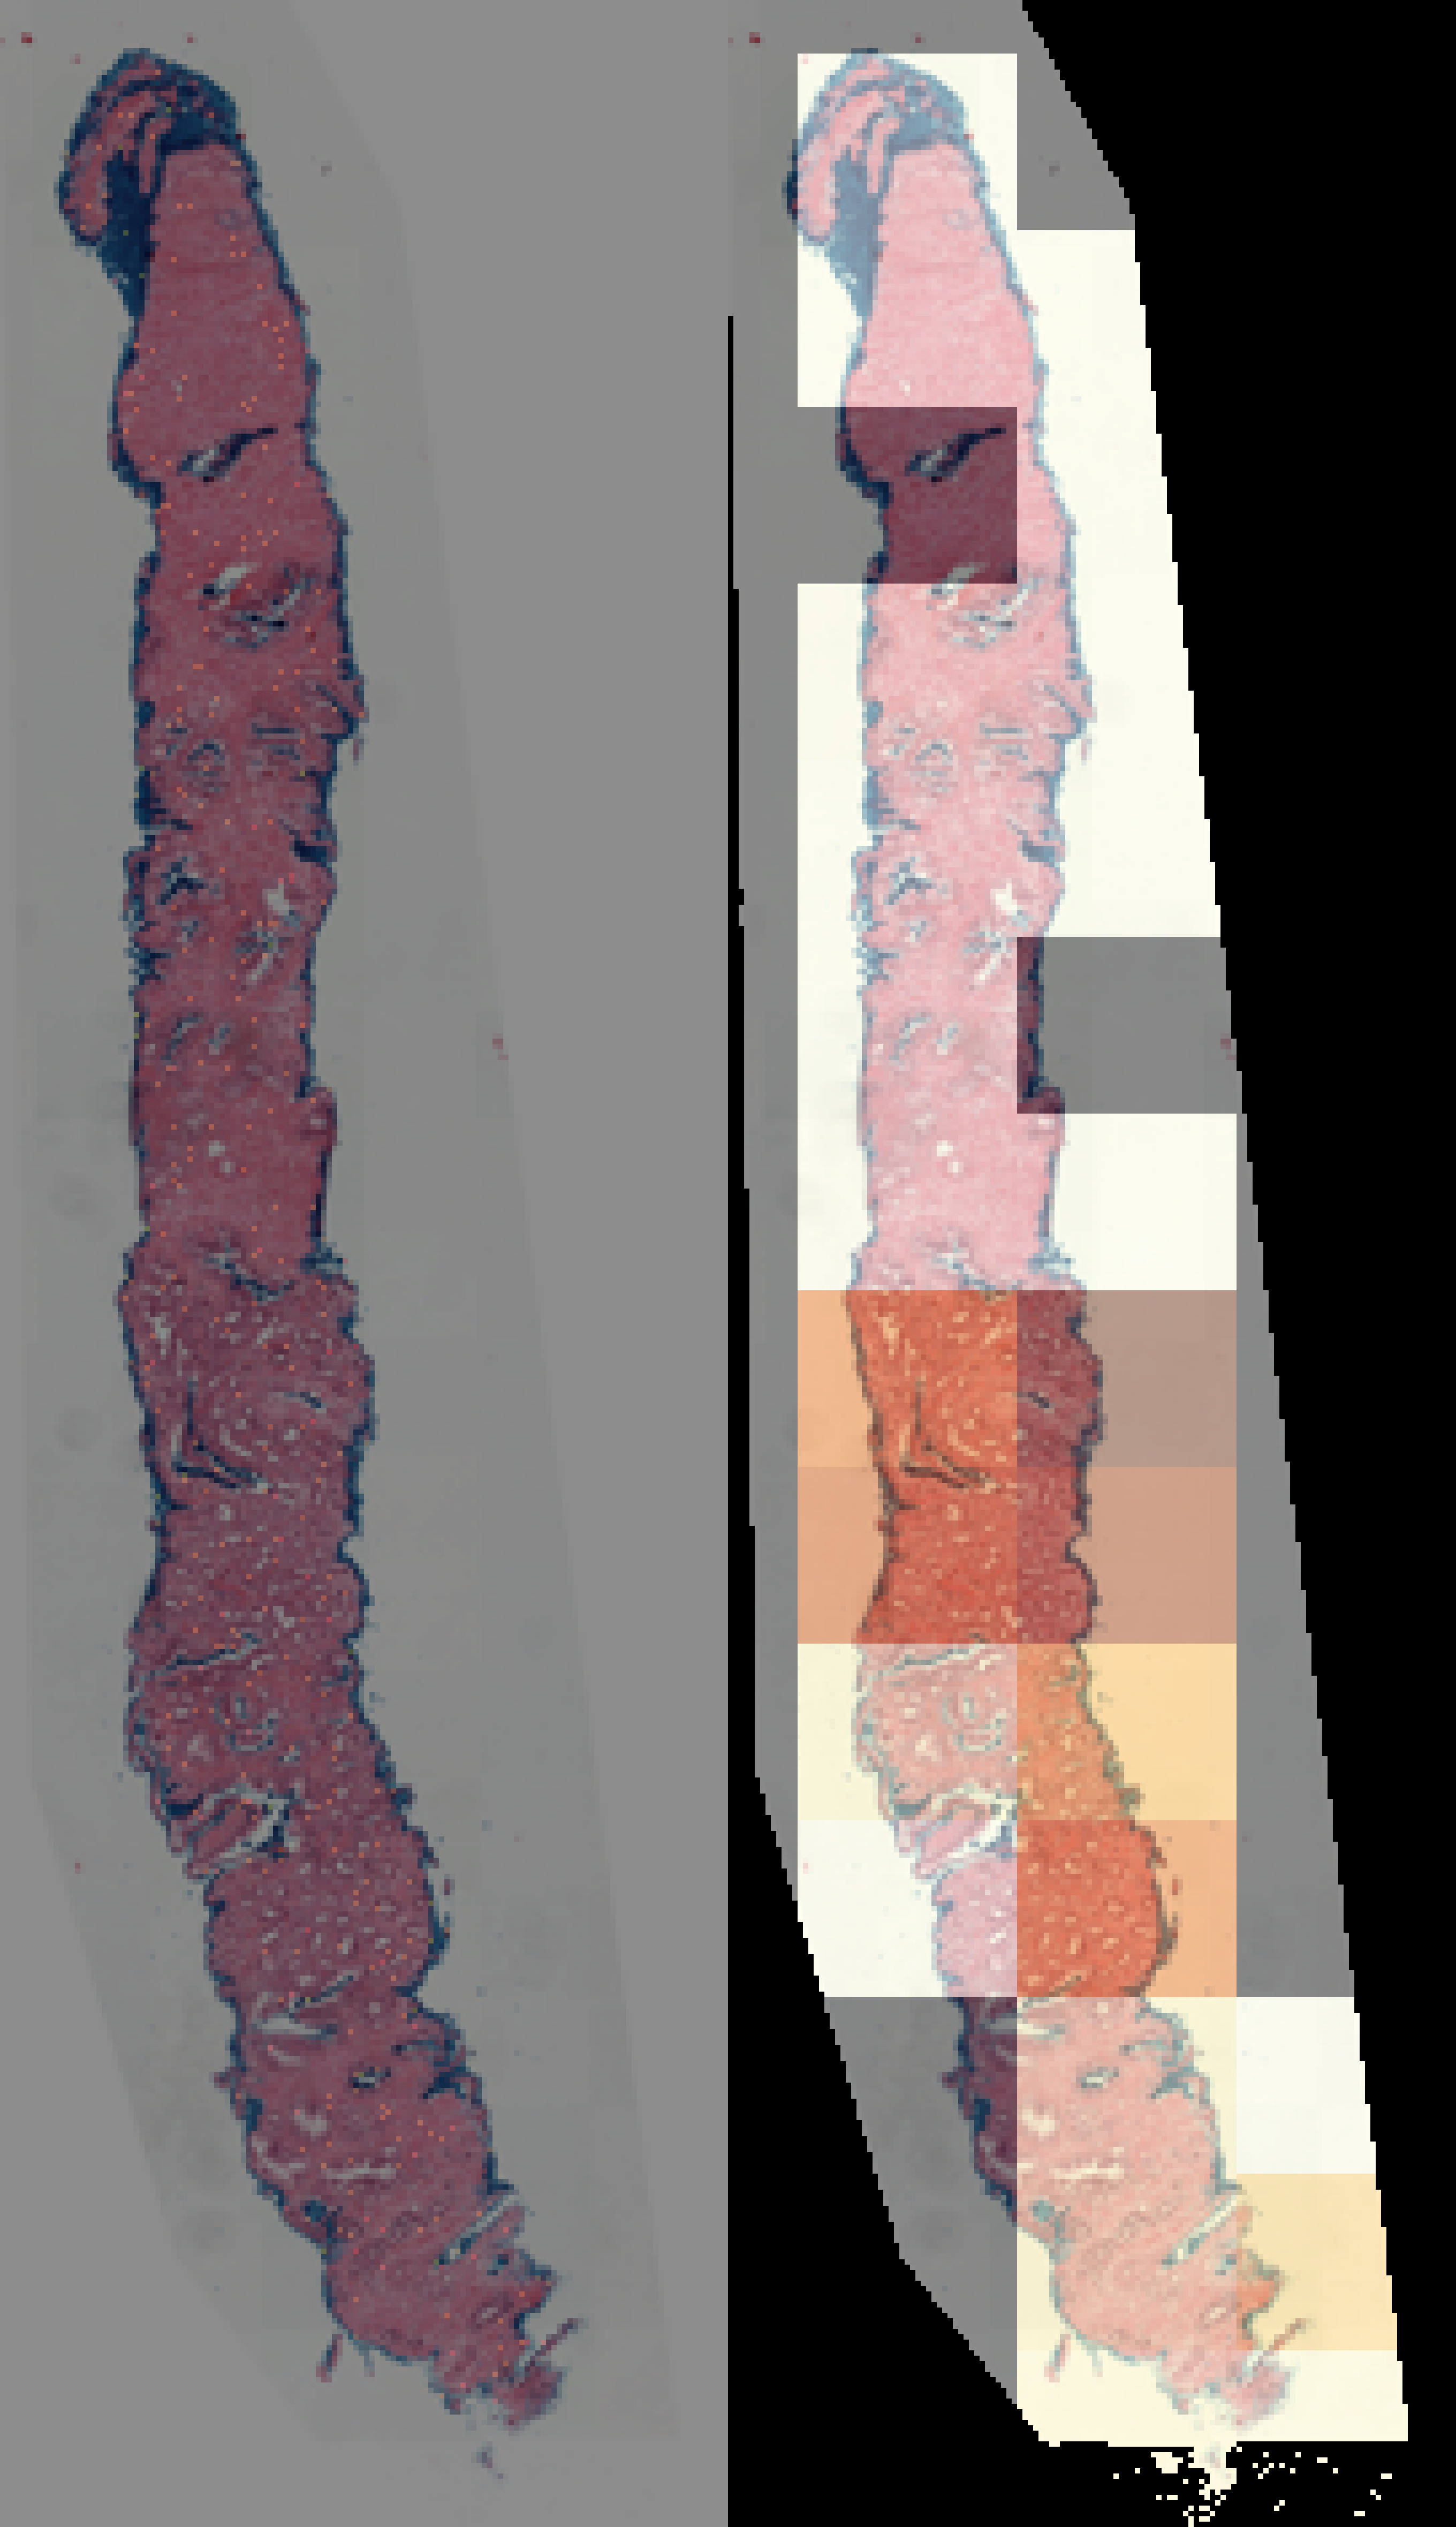

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/01227af585a47c16680f927d21a7f06a.png
 Cargando WSI desde: /workspace/data/pandas/stitches/019c1b40e6ec7410e8356c5d8d487954.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/01afe81220f729cf1c5b4d99f3abe559.png 
slide /workspace/data/pandas/patches/01afe81220f729cf1c5b4d99f3abe559.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 5.


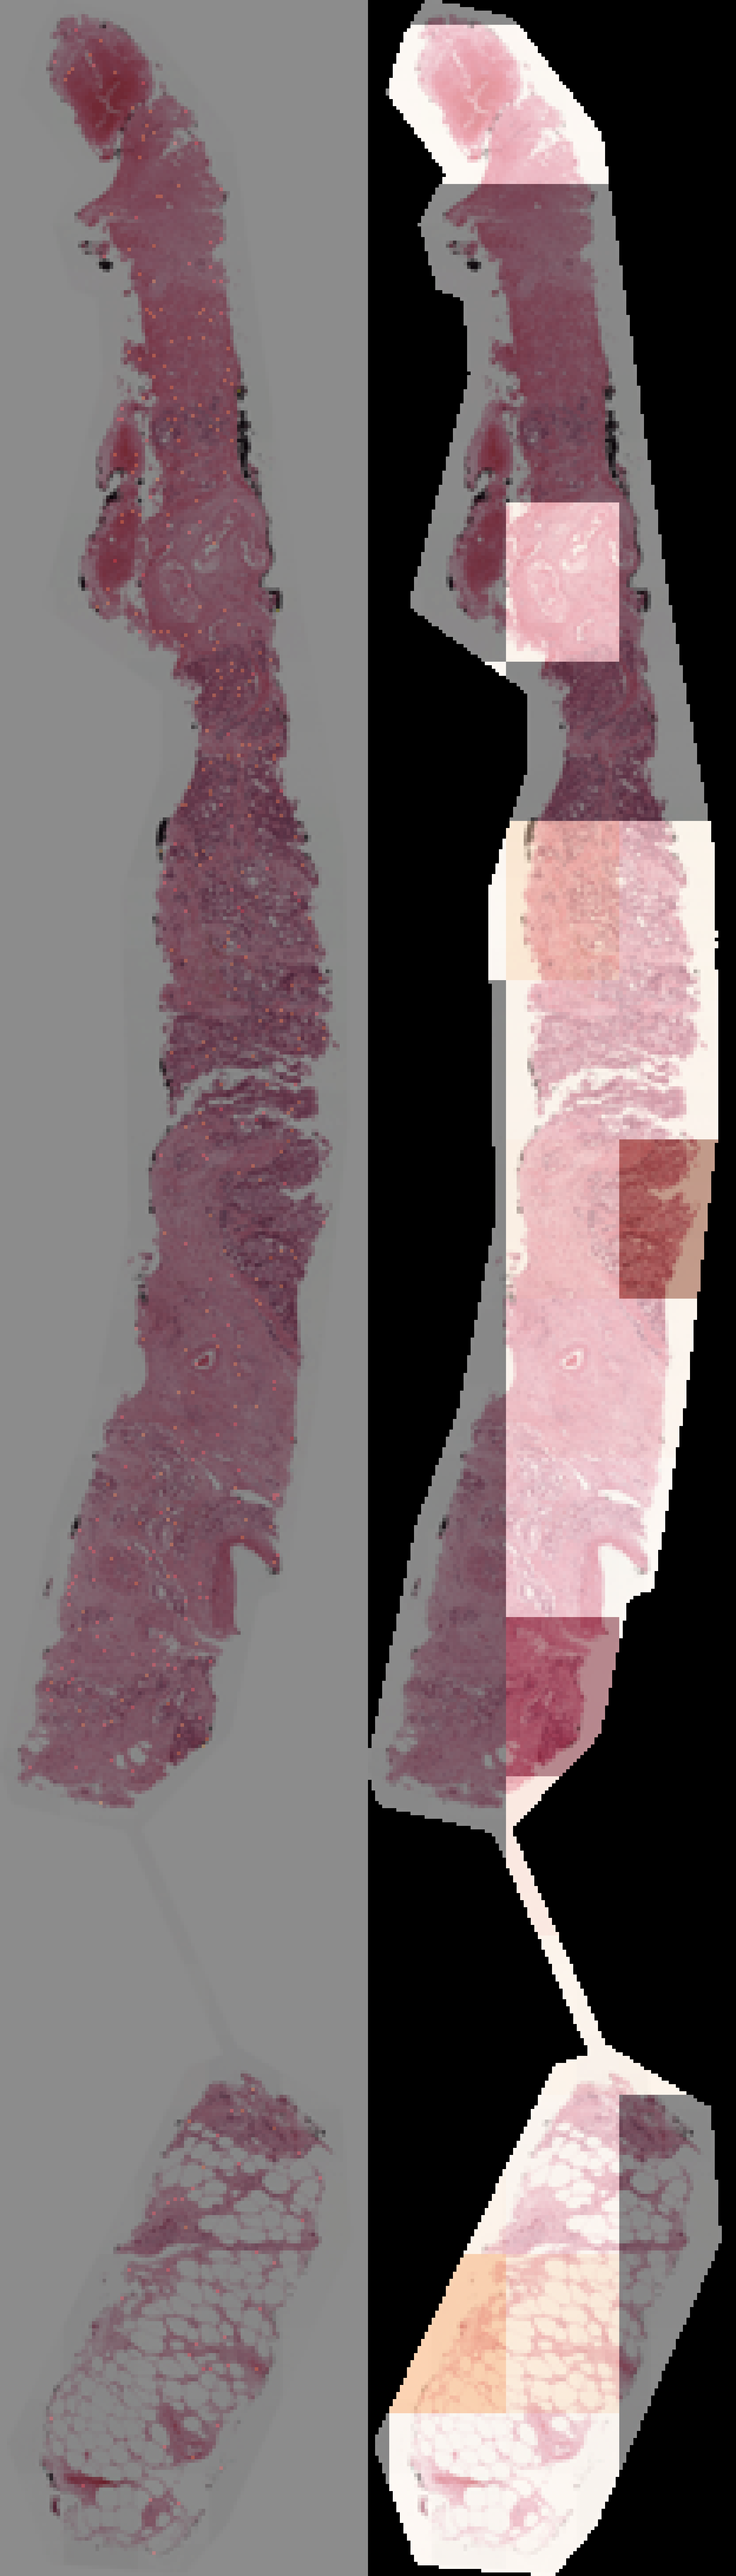

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/01afe81220f729cf1c5b4d99f3abe559.png
 Cargando WSI desde: /workspace/data/pandas/stitches/01c816336959ee9d94b23b37b0f71f21.png 


/usr/local/lib/python3.10/dist-packages/PIL/Image.py:3035: DecompressionBombWarning: Image size (137166848 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


slide /workspace/data/pandas/patches/01c816336959ee9d94b23b37b0f71f21.h5
 Scores de la slide: Grado Primario = NC & Grado Secundario = NC.


Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/01c816336959ee9d94b23b37b0f71f21.png
 Cargando WSI desde: /workspace/data/pandas/stitches/01d20d68bce47bec01d816b893630f18.png 
slide /workspace/data/pandas/patches/01d20d68bce47bec01d816b893630f18.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


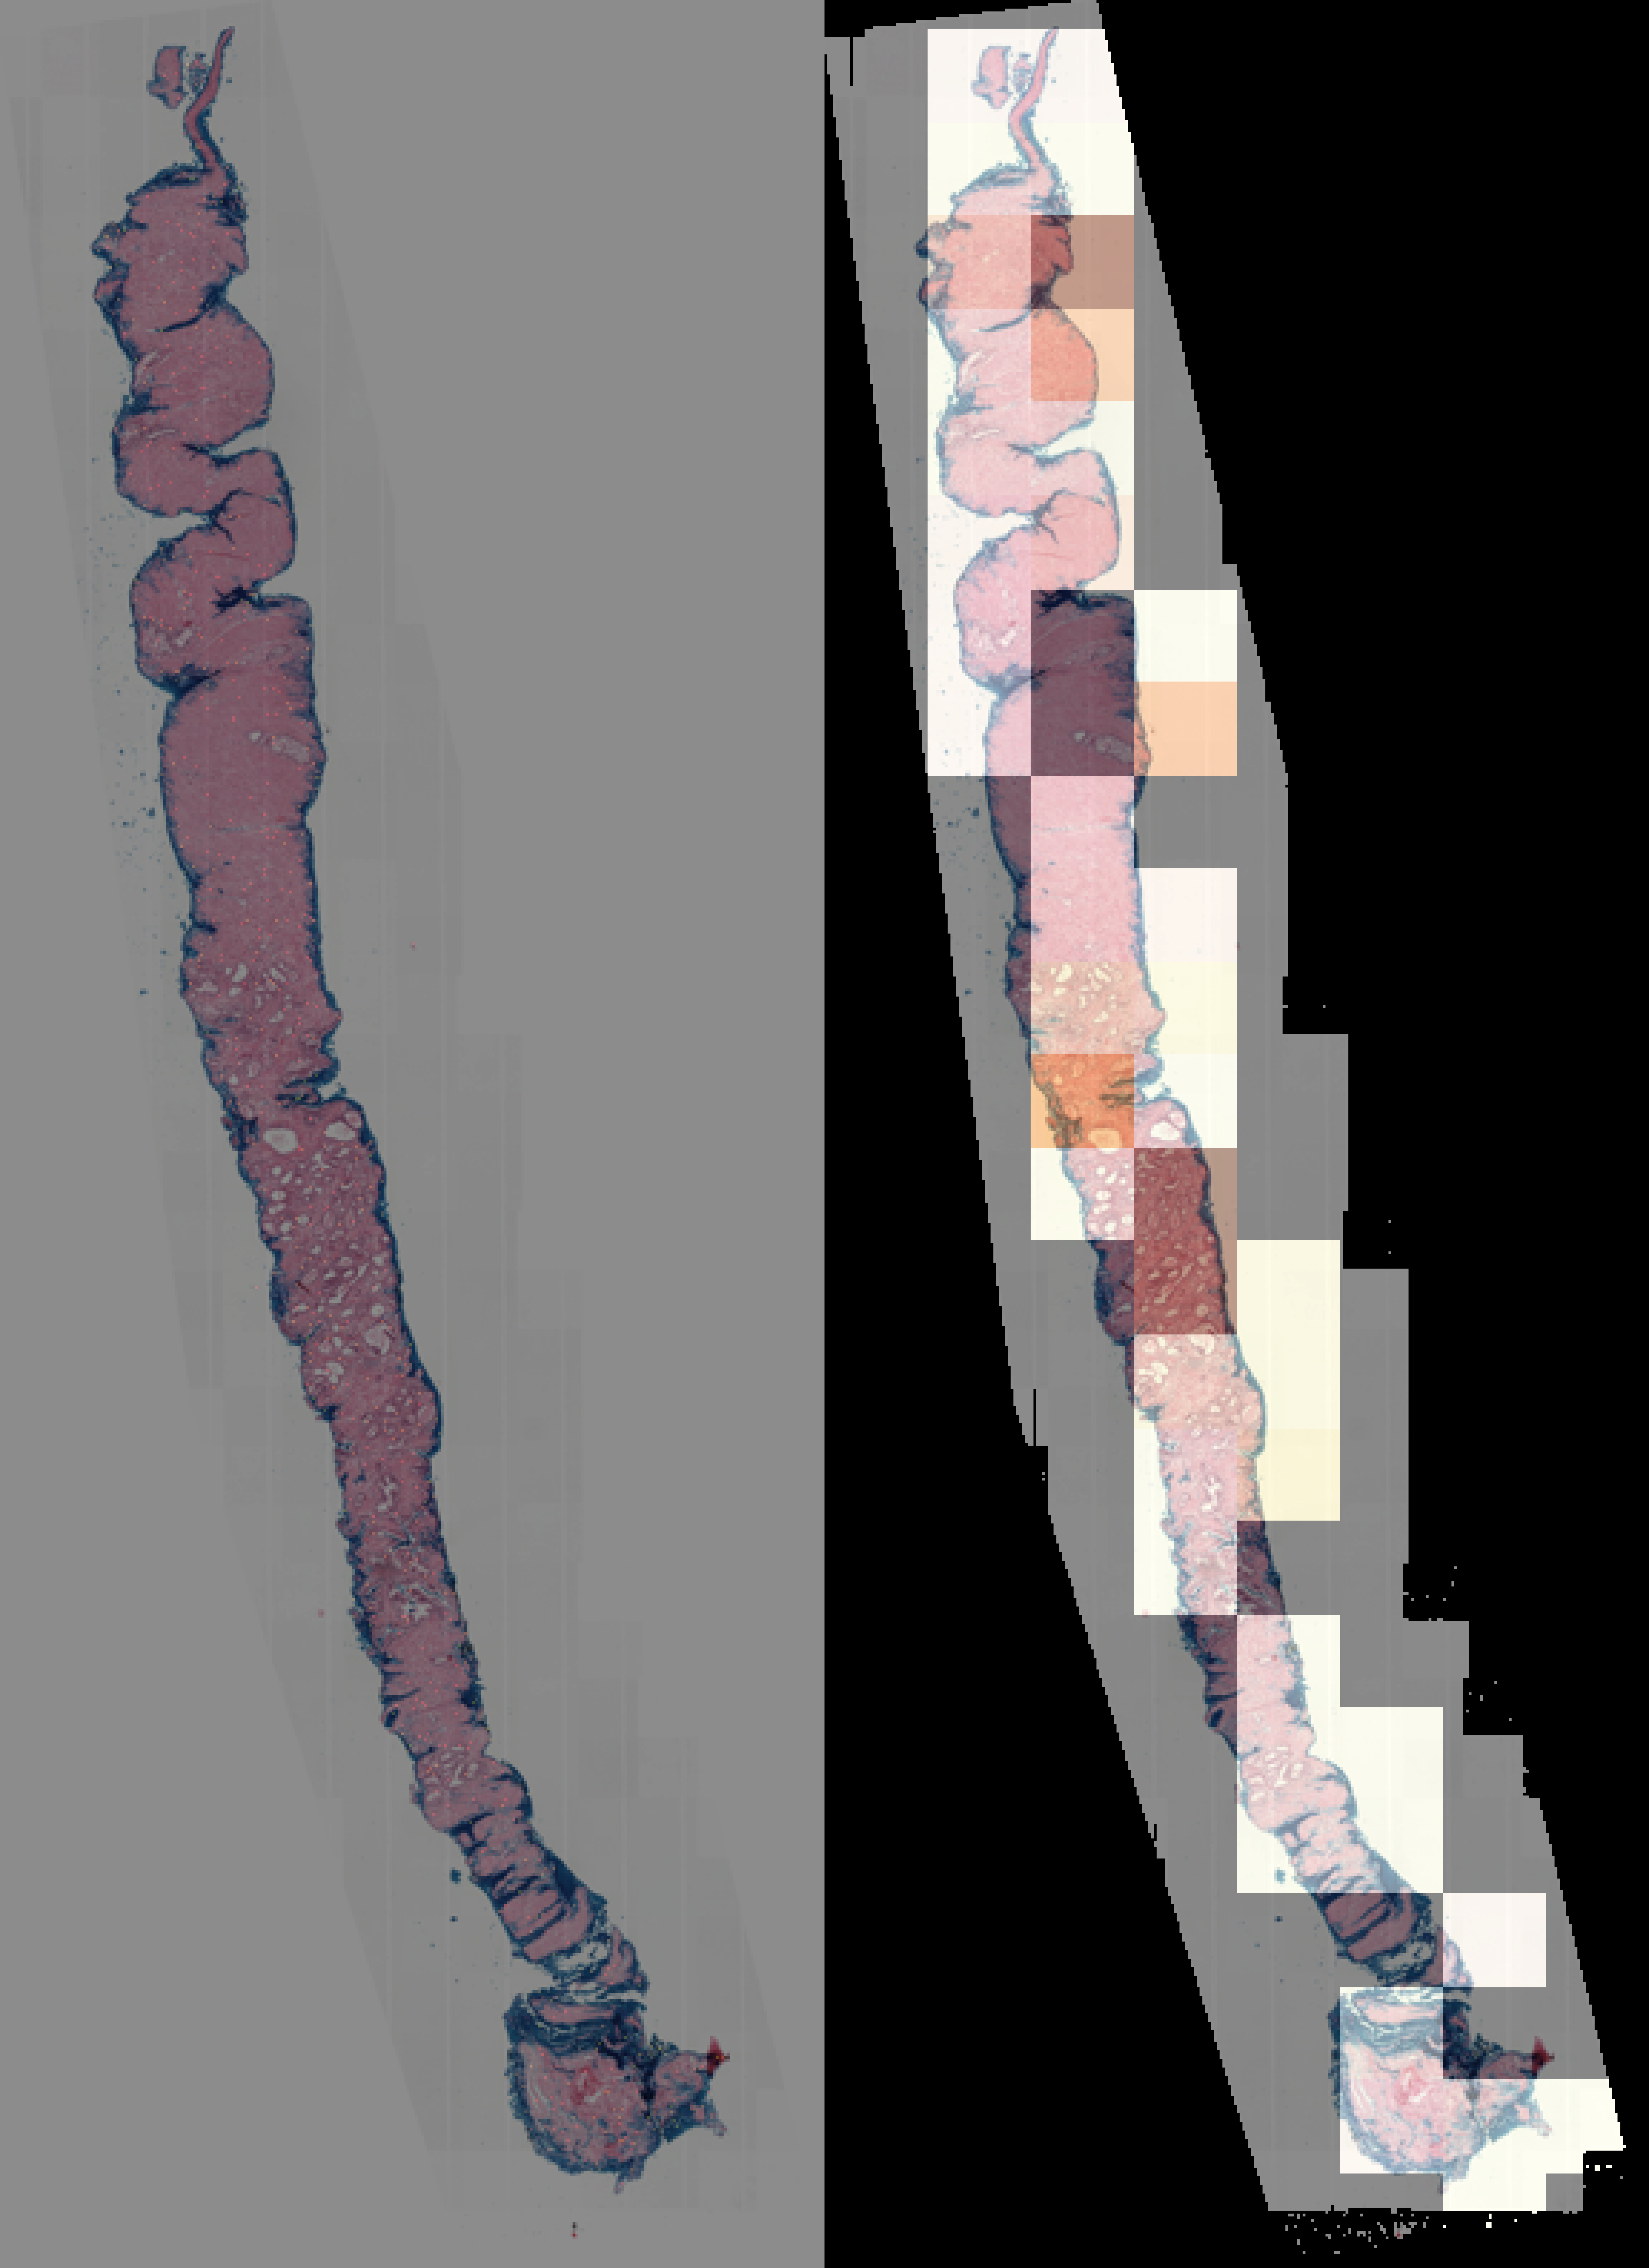

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/01d20d68bce47bec01d816b893630f18.png
 Cargando WSI desde: /workspace/data/pandas/stitches/01d647e17ee868d2991c73a247c28cf9.png 
slide /workspace/data/pandas/patches/01d647e17ee868d2991c73a247c28cf9.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


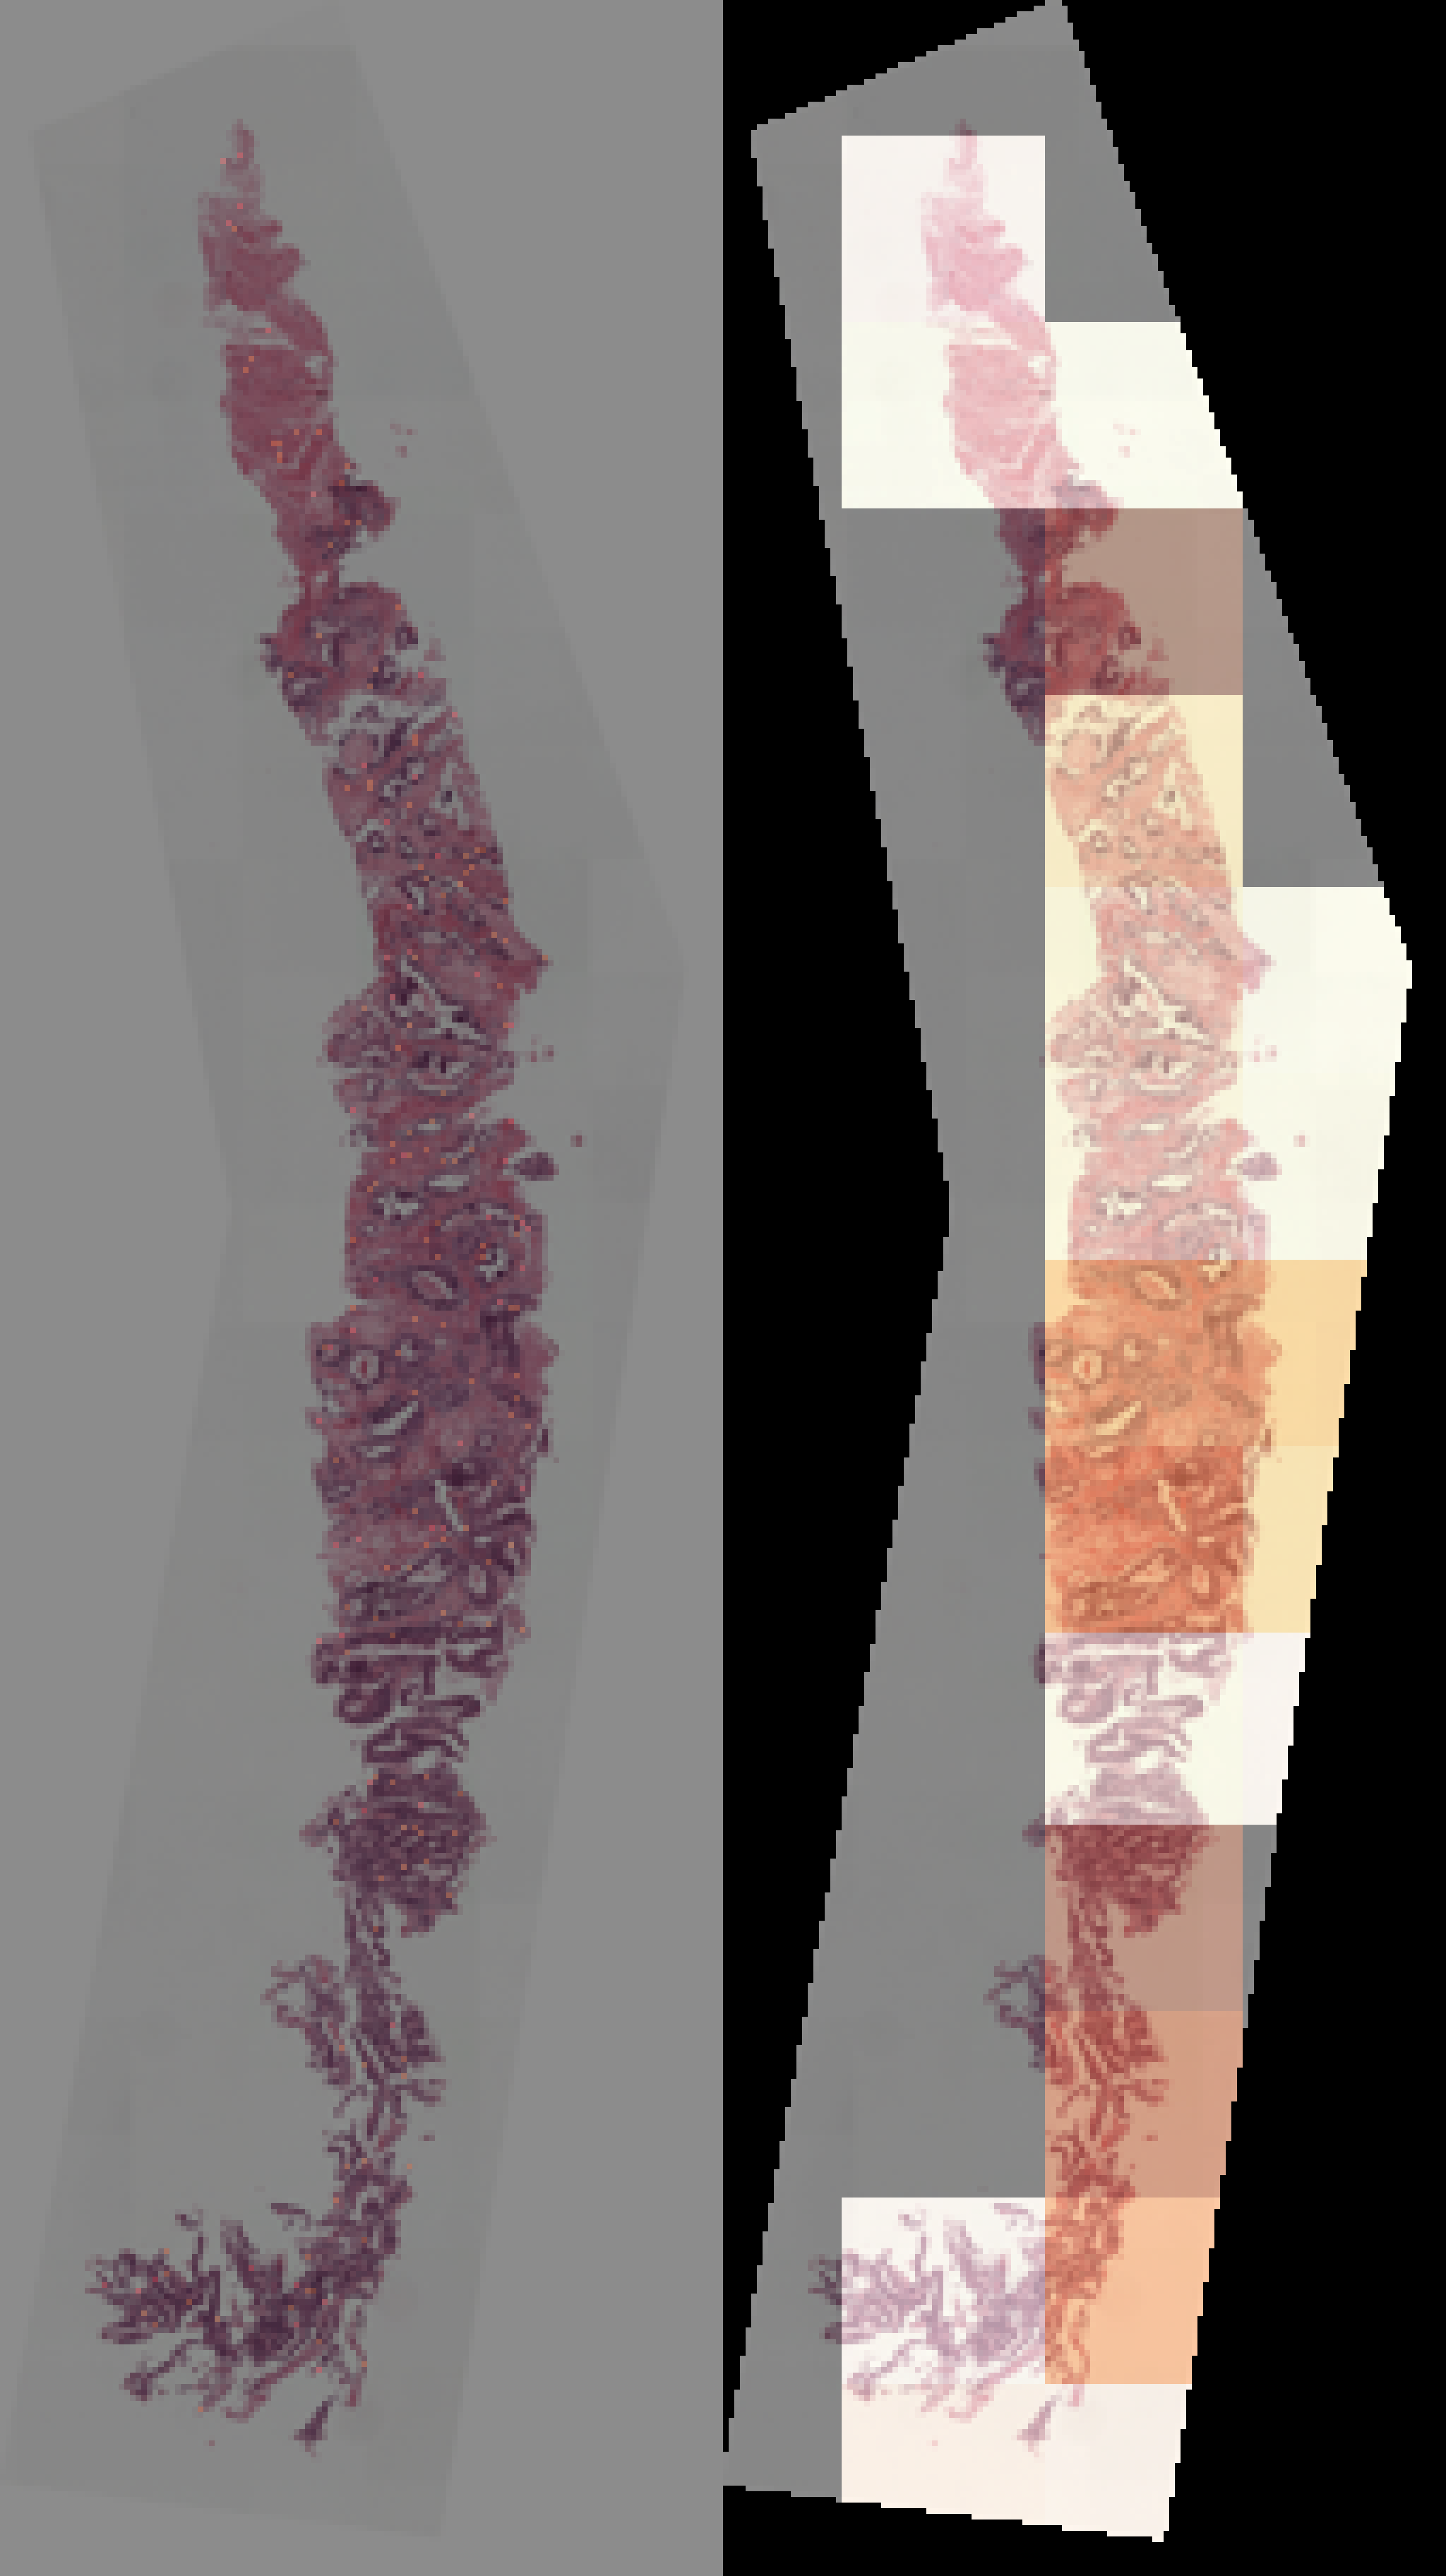

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/01d647e17ee868d2991c73a247c28cf9.png
 Cargando WSI desde: /workspace/data/pandas/stitches/01faa9d3bc7a2464c7b6d71ea904970f.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/020d0243094c8561544f683b4c64859d.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/02a2dcd6ad8bc1d9ad7fdc04ffb6dff3.png 
slide /workspace/data/pandas/patches/02a2dcd6ad8bc1d9ad7fdc04ffb6dff3.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 5.


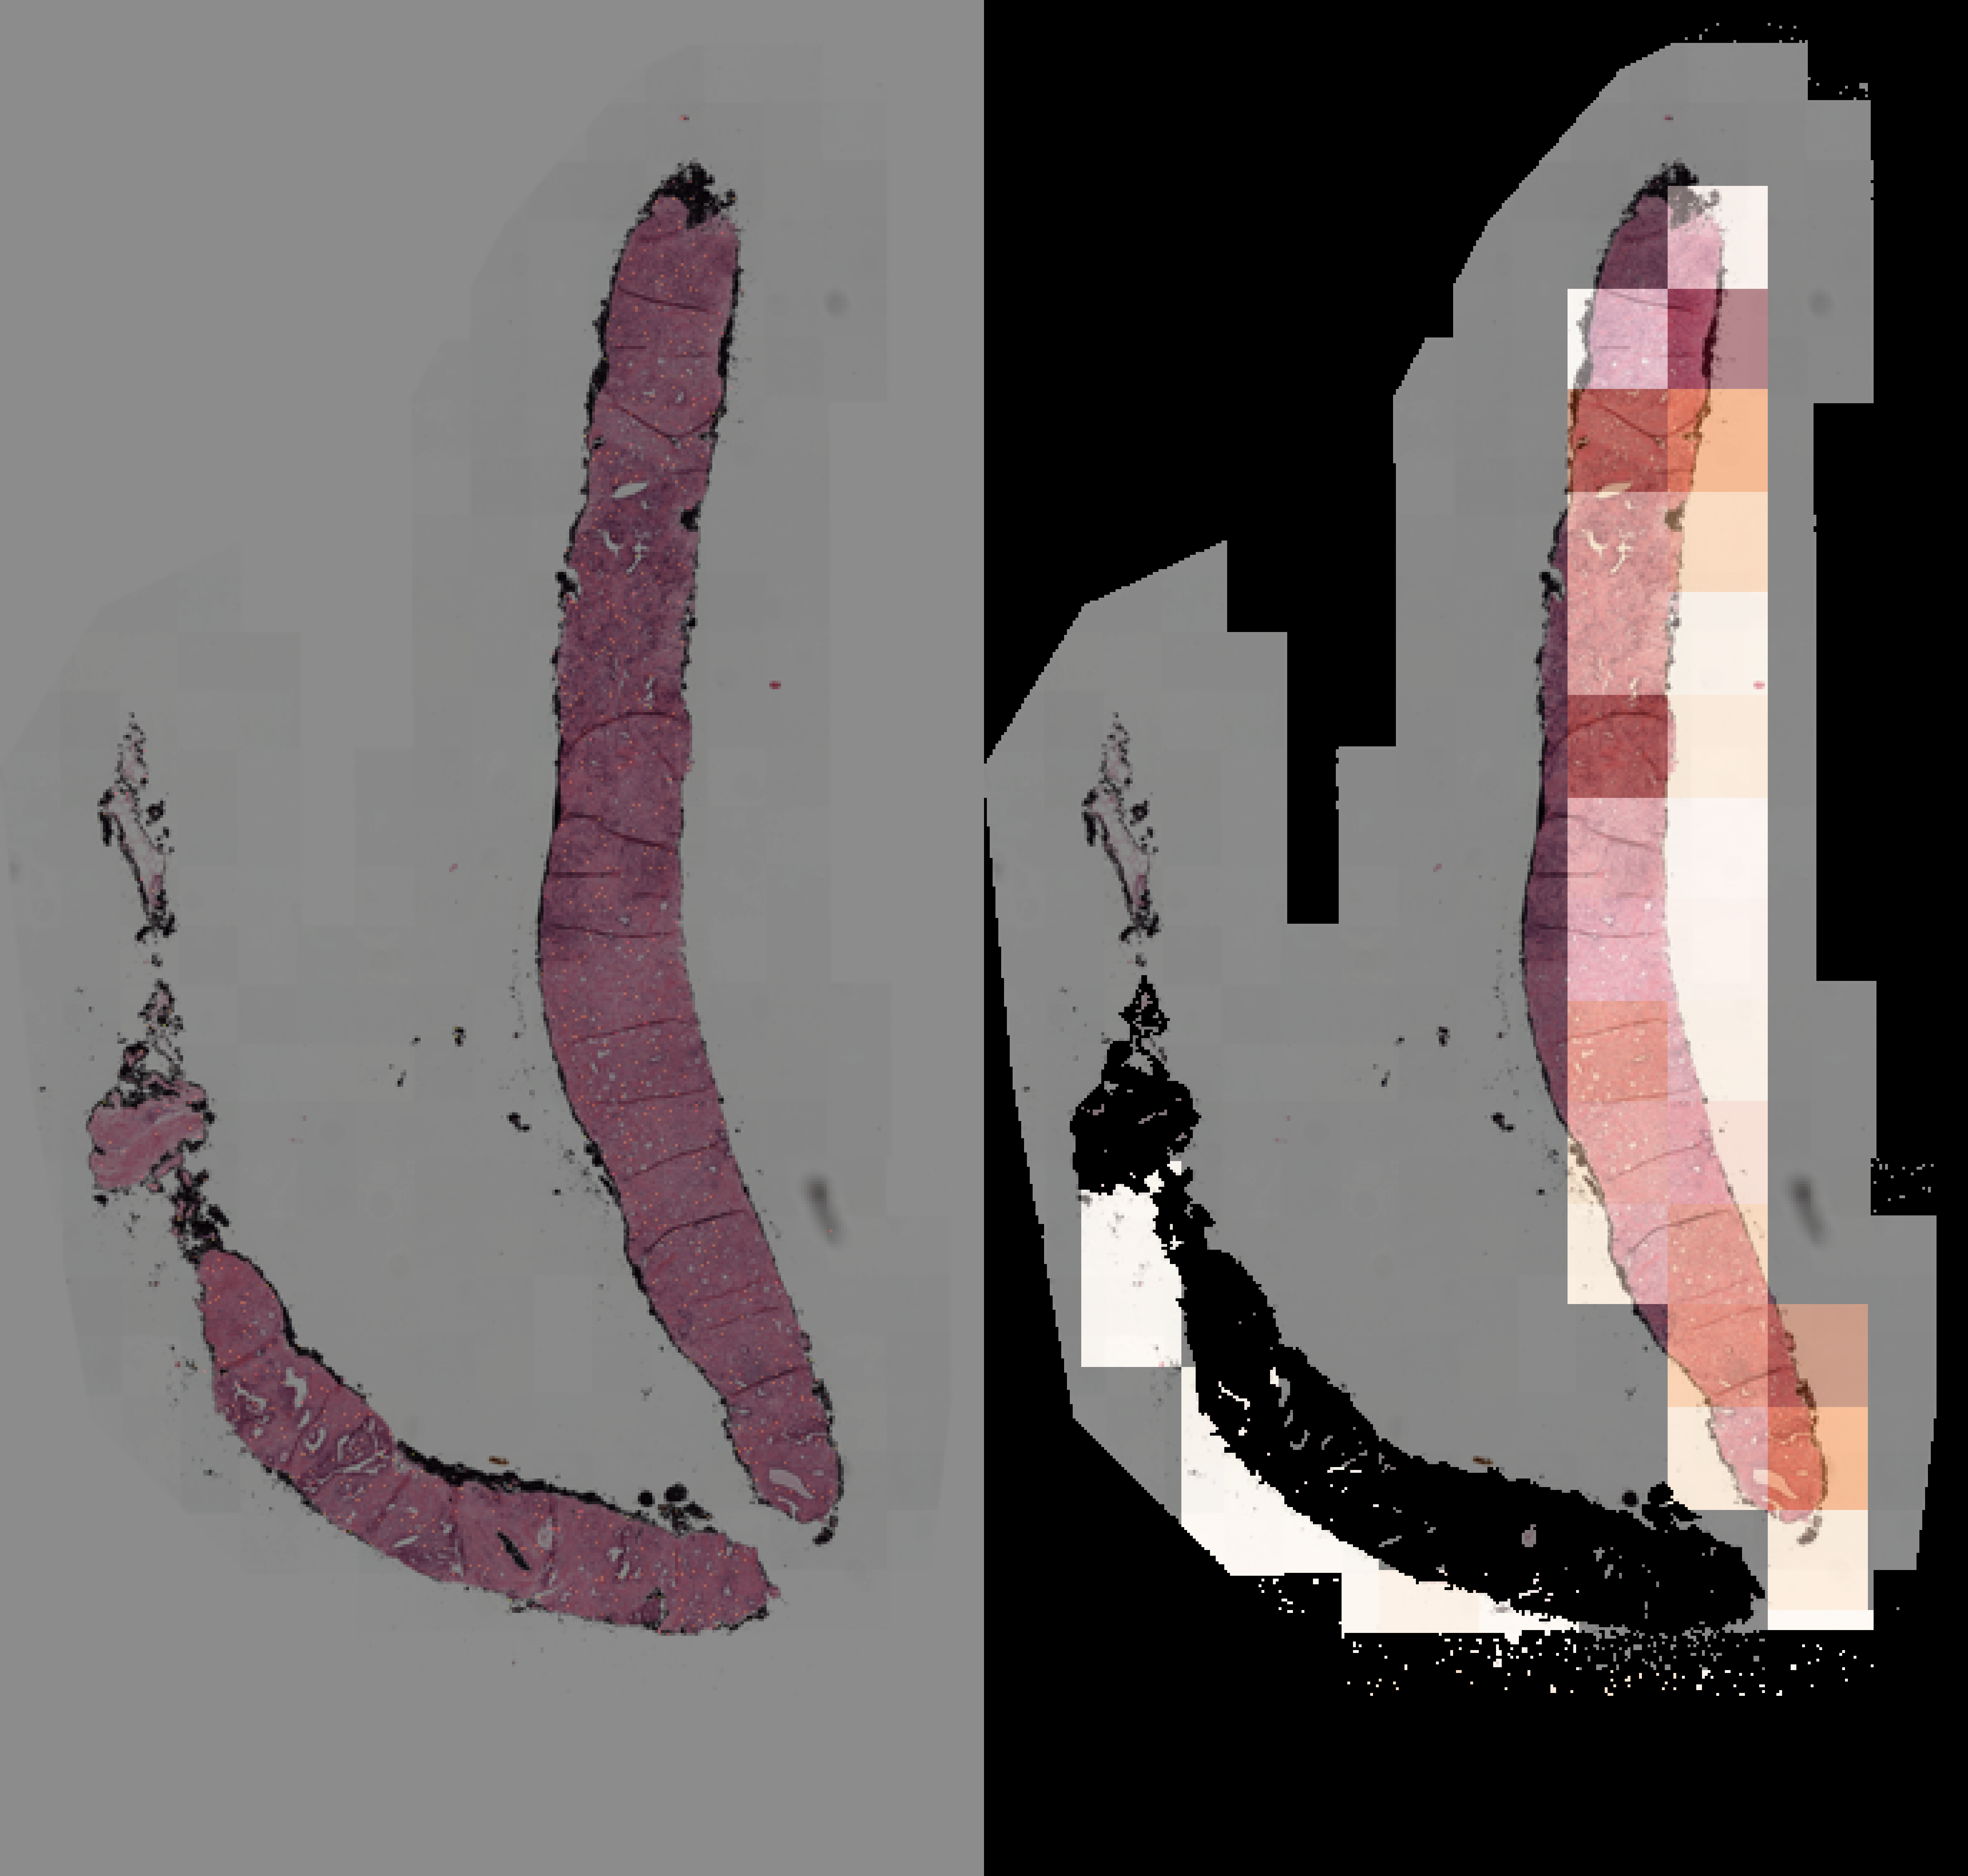

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/02a2dcd6ad8bc1d9ad7fdc04ffb6dff3.png
 Cargando WSI desde: /workspace/data/pandas/stitches/02c2141567e50ff7d04069f70e9c9c5e.png 


/usr/local/lib/python3.10/dist-packages/PIL/Image.py:3035: DecompressionBombWarning: Image size (120913920 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


slide /workspace/data/pandas/patches/02c2141567e50ff7d04069f70e9c9c5e.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.


Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/02c2141567e50ff7d04069f70e9c9c5e.png
 Cargando WSI desde: /workspace/data/pandas/stitches/02ed1bc414852efe74deb5a44bb86336.png 


/usr/local/lib/python3.10/dist-packages/PIL/Image.py:3035: DecompressionBombWarning: Image size (100948584 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


slide /workspace/data/pandas/patches/02ed1bc414852efe74deb5a44bb86336.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 3.


Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/02ed1bc414852efe74deb5a44bb86336.png
 Cargando WSI desde: /workspace/data/pandas/stitches/03692c5859b1eb7af0f4292e10586205.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/03717c12ffe242a347cdfd9d13e6cd76.png 
 Cargando WSI desde: /workspace/data/pandas/stitches/04e1a953bceb9b1a0a5bf8840614aa04.png 


/usr/local/lib/python3.10/dist-packages/PIL/Image.py:3035: DecompressionBombWarning: Image size (166381800 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


slide /workspace/data/pandas/patches/04e1a953bceb9b1a0a5bf8840614aa04.h5
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/04e1a953bceb9b1a0a5bf8840614aa04.png
 Cargando WSI desde: /workspace/data/pandas/stitches/05abe25c883d508ecc15b6e857e59f32.png 
slide /workspace/data/pandas/patches/05abe25c883d508ecc15b6e857e59f32.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.




Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/05abe25c883d508ecc15b6e857e59f32.png
 Cargando WSI desde: /workspace/data/pandas/stitches/05b09773ad1b34275f0b5adee3c650ab.png 
slide /workspace/data/pandas/patches/05b09773ad1b34275f0b5adee3c650ab.h5
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.


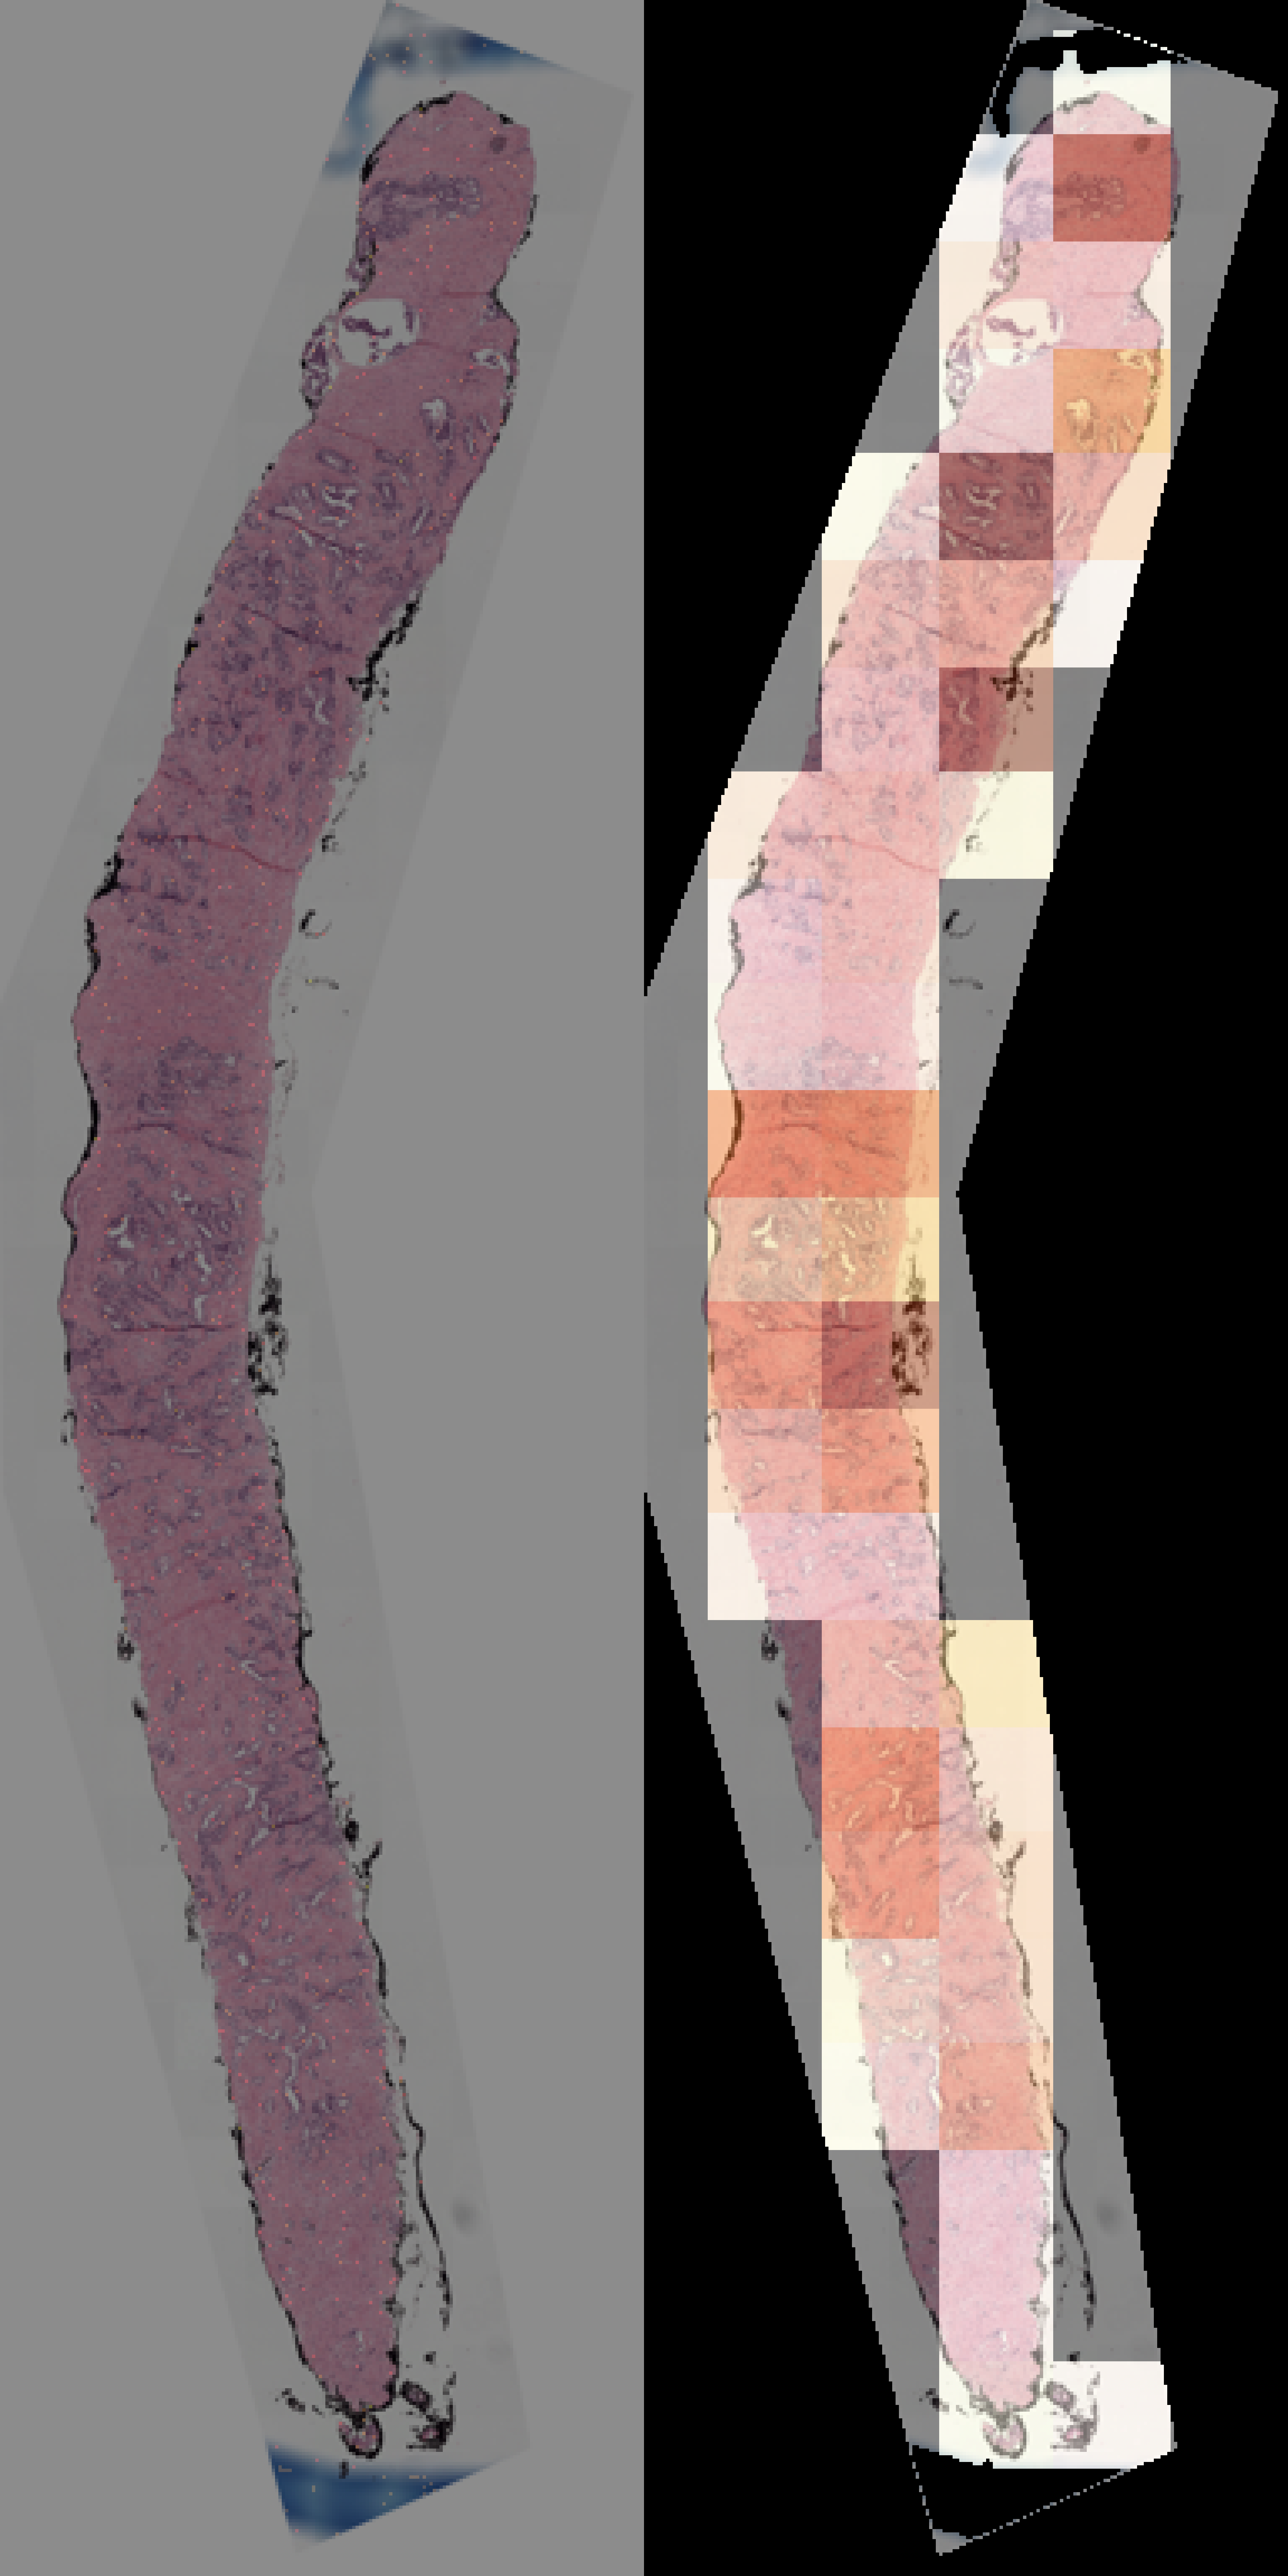

Guardando heatmap en : ... /workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100/heatmaps_PANDA/05b09773ad1b34275f0b5adee3c650ab.png


In [27]:
import os 
#urrent_dir  = os.path.abspath(os.getcwd()) # Directorio actual
#sys.path.append(os.path.dirname(current_dir))
from utils.heatmap_utils import gt_building,   overlay_heatmap_on_image, draw_gt_patches, overlay_inside_green_line
test_outputs = test_outputs.head(20)
dataset = 'PANDA'
factor = 16
folder_original_imgs = '/workspace/data/pandas/stitches'
num_img_show = 20

sicap_images_folder_path='/workspace/data/pandas/patches' #'/workspace/data/TCGA/patches'' #'/workspace/data/features_SICAP/patches' 
sicap_labels_df_path=  '/workspace/data/datos_PANDAS.xlsx' #  '/workspace/data/wsi_labels_changed_SICAP.xlsx' #'/workspace/data/features_PRAD/tcga_dataset.xlsx' # 
mask_folder= '/workspace/data/pandas/stitches' 
mask_folder= '/workspace/data/pandas/stitches' #"/workspace/data/annotation_masks_SICAP" #'/workspace/data/TCGA/stitches'
folder_original_imgs = '/workspace/data/pandas/stitches' #'/workspace/data/slides_filter'
green_folder = '/workspace/data/pandas/stitches'  #'/workspace/data/features_SICAP/masks'#'/workspace/data/TCGA/masks' 

for index, row in test_outputs.iterrows():

    slide_id = row['slide_id']
     # Cargar la WSI original 
    slide_id = slide_id.replace('.h5','')+ '.png'  #'.jpg'  # Ajustar extensión si es necesario
    file_name = slide_id.split('/')[-1]
    wsi_path = os.path.join(folder_original_imgs,file_name)
    print(f" Cargando WSI desde: {wsi_path} ")
    
    try: 
        orig, green, h, w = gt_building(wsi_path, green_folder, dataset= dataset, file_name=slide_id,factor = factor )
    except:
        continue
    mask, w_mask = build_heatmap_binary(coords = row['coords'], weights=row['weights'],scores = row['scores'],height = h, width=w, patch_size=512, scale_factor=factor)
   
    print('slide',row['slide_id'])

    #pred_primary, pred_secondary = select_gleason_grades_from_batch_proportions(proportions=row['wsi_logits'], min_presence_thresh=0.05, secondary_ratio_thresh=0.5)
    pred_primary, pred_secondary = row['wsi_logits'][0], row['wsi_logits'][1]
    if pred_primary == pred_secondary:
        grades = [pred_primary]
    else:
        grades = [pred_primary, pred_secondary]
    labels_dic = {0: "NC", 1: "Grade 3", 2: "Grade 4", 3: "Grade 5"}
    pred_primary = labels_dic.get(pred_primary.item())
    pred_secondary = labels_dic.get(pred_secondary.item())
    print(f" Scores de la slide: Grado Primario = {pred_primary} & Grado Secundario = {pred_secondary}.")
    # Imagen acumuladora (RGB)
    heatmap = heatmap_building(h,w, mask, w_mask, grades, factor = factor,slide_id = slide_id )
    
    #Crear overlay heatmap sobre la imagen
    overlay = overlay_heatmap_on_image(orig, heatmap)
    overlay_green = overlay_inside_green_line(green,overlay,green_thresh=(200, 255, 255))#(150, 100, 100))

    # Dibujar parches GT en la imagen real (lado izquierdo)
    orig_with_gt = draw_gt_patches(orig.copy(), file_name, mask_folder)

    # Crear imagen lado a lado
    w2, h2 = orig_with_gt.size
    w2 = w2*10
    h2 = h2*10
    orig_with_gt = orig_with_gt.resize((w2 ,h2), resample=Image.Resampling.NEAREST)
    overlay_green = overlay_green.resize((w2 ,h2), resample=Image.Resampling.NEAREST)
    canvas = Image.new("RGB",(w2*2, h2)) #(w2*2, h2))
    canvas.paste(orig_with_gt, (0, 0))
    canvas.paste(overlay_green, (w2, 0), overlay_green)

    canvas.show()
    out_name = row['slide_id'].replace('.h5', '.png')
    out_name = out_name.split('/')[-1]
    print(f"Guardando heatmap en : ... {os.path.join('/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100',f'heatmaps_{dataset}',out_name )}")
    canvas.save(os.path.join('/workspace/results/20260127_113137_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-100',f'heatmaps_{dataset}',out_name ), dpi=(300, 300))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# -----------------------------
# CONFIGURACIÓN
# -----------------------------

excel_gt = "/workspace/data/wsi_labels_changed_SICAP.xlsx"
df_pred = test_outputs.copy()

# -----------------------------
# CARGA DE DATOS
# -----------------------------

df_pred["image_id"] = (
    df_pred["slide_id"]
    .apply(lambda x: os.path.basename(x))   # 16B0003388_13.h5
    .str.split(".h5").str[0]    # 16B0003388_13
    .str.split("_").str[0]                  # 16B0003388
)
# GT
df_gt = pd.read_excel(excel_gt)
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# 1. Merge GT y predicciones
# =========================
df = df_gt.merge(
    df_pred,
    left_on="image_id",
    right_on="image_id",
    how="inner"
)

# =========================
# 2. Extraer predicciones
# =========================
# Primary y secondary desde wsi_logits
df["pred_primary"] = df["wsi_logits"].apply(lambda x: x[0].item())
df["pred_secondary"] = df["wsi_logits"].apply(lambda x: x[1].item())

# Gleason score como suma de logits
df["pred_gleason_score"] = df["wsi_logits"].apply(lambda x: sum(x).item())

# ------------------------------------------------------------------
# ⚠️ SI LOS LOGITS NO SON CLASES ENTERAS, discretiza aquí
# Ejemplo:
df["pred_primary"] = df["pred_primary"].round().astype(int)
df["pred_secondary"] = df["pred_secondary"].round().astype(int)
df["pred_gleason_score"] = df["pred_gleason_score"].round().astype(int)
# ------------------------------------------------------------------

# =========================
# 3. Matrices de confusión
# =========================

# 1️⃣ Gleason score vs suma de wsi_logits
cm_score = confusion_matrix(
    df["gleason_score"],
    df["pred_gleason_score"], labels=[6,7,8,9,10]
)

# 2️⃣ Gleason primary vs primer logit
cm_primary = confusion_matrix(
    df["gleason_primary"],
    df["pred_primary"], labels= [0,1,2,3]
)

# 3️⃣ Gleason secondary vs segundo logit
cm_secondary = confusion_matrix(
    df["gleason_secondary"],
    df["pred_secondary"], labels= [0,1,2,3]
)

# =========================
# 4. Visualización
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(cm_score).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Gleason score vs sum(wsi_logits)")

ConfusionMatrixDisplay(cm_primary).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Gleason primary vs wsi_logits[0]")

ConfusionMatrixDisplay(cm_secondary).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Gleason secondary vs wsi_logits[1]")

plt.tight_layout()
plt.show()
